# NASCAR Next-Lap Pace Prediction (V1)

**Goal:** Predict a Cup Series driver's next green-flag lap time during a race, using only information available at that moment.

**Data:** Lap-by-lap timing, pit stop, and caution data from the Michigan International Speedway Cup races (2021–2026), pulled with [pynascar](https://github.com/), an open-source Python wrapper for NASCAR race data.
Track lengths come from `cup_tracks.csv` (included in this repository).

**Objectives:**
- Engineer race-aware features: tire age (right and left side), pace within each green-flag run, pace trend (tire falloff), and pace relative to the field
- Predict the *lap-to-lap change* in pace with an XGBoost regression model
- Train on 2021–2024, test on unseen 2025–2026 races

**Result:** Test MAE of **0.166 seconds**, about **12% better** than the strongest simple baseline (predicting the next lap equals the current lap).

See the README for full design decisions, experiments, and limitations.

In [1]:
# Imports
################################################
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt                     # Charts (model vs. baselines, feature importance)
from pynascar import Schedule, Race                 # NASCAR race data: schedules, lap times, pit stops, cautions
from sklearn.metrics import mean_absolute_error     # Model evaluation
from xgboost import XGBRegressor                    # Tree model

# Load Data
# Raw race data originally pulled with pynascar (see fetch_data.ipynb)
# Each file contains all Michigan races; the race_id column identifies the race
################################################
lap_times_all = pd.read_csv('data/michigan_lap_times.csv')       # Lap-by-lap times, speeds, positions
pit_stops_all = pd.read_csv('data/michigan_pit_stops.csv')       # Pit stops and stop type (4-tire, 2-tire, other)
cautions_all = pd.read_csv('data/michigan_cautions.csv')         # Caution periods (start/end lap, reason)
race_metadata = pd.read_csv('data/michigan_race_metadata.csv')   # Season, scheduled laps, stage lengths

# Track lengths (used to convert lap speed → lap time)
cup_tracks = pd.read_csv('data/cup_tracks.csv')          # Included in this repository


## 1. The Races
This project uses the six NASCAR Cup Series races at Michigan International Speedway from 2021–2026.
- **Training:** 2021–2024 (2021 race used the previous-generation Gen-6 car; it's kept because more data improved the model)
- **Testing:** 2025–2026 (races not seen by the model, to measure how well the model predicts the future)

In [2]:
# Michigan Races in This Project
# Each race has a unique race_id, used below to split races into training and test sets
################################################
race_metadata[['race_season', 'race_id', 'race_name', 'race_date', 'scheduled_laps']].sort_values('race_season')

,race_season,race_id,race_name,race_date,scheduled_laps
0,2021,5031,FireKeepers Casino 400,2021-08-22T15:00:00,200
1,2022,5170,FireKeepers Casino 400,2022-08-07T15:00:00,200
2,2023,5296,FireKeepers Casino 400,2023-08-06T14:30:00,200
3,2024,5415,FireKeepers Casino 400,2024-08-18T14:30:00,200
4,2025,5573,FireKeepers Casino 400,2025-06-08T14:00:00,200
5,2026,5612,FireKeepers Casino 400,2026-06-07T15:00:00,200


## 2. Features and Target
**Features** describe car's status at the time of prediction: recent pace, tire wear, and race situation.

**Target:** The *change* from the current lap (e.g. +0.04 s). This lets the model focus on what drives pace changes (tire falloff, end-of-stage behavior, traffic) rather than each car's overall lap speed.

**Features tested and removed:** `Lap`, `laps_remaining`, and `current_pos_group` were removed because they did not improve test accuracy.

In [3]:
# Model Features
# All features use only information available at the moment of prediction (no future data)
################################################
features = [
    # Current pace
    'laptime',                            # Lap just completed
    'driver_last_valid_laptime',          # Previous valid lap in this run
    'driver_rolling_3_lap_pace',          # Avg of last 3 valid laps in this run
    'driver_rolling_5_lap_pace',          # Avg of last 5 valid laps in this run
    'driver_pace_trend',                  # Slope of recent laps: (+) = slowing (tire falloff), (-) = speeding up
    'driver_relative_pace_to_field',      # Rolling-5 pace vs. the field median (-) = faster than field)

    # Tires
    'right_tire_age',                     # Green-flag laps since right-side tires were changed
    'left_tire_age',                      # Green-flag laps since left-side tires were changed

    # Race situation
    'position',                           # Current running position
    'position_change',                    # Positions gained (+) or lost (-) since last lap
    'scheduled_laps_remaining_in_stage',  # Laps left in the current stage (strategy / fuel saving)
    'green_flag_run_length',              # Laps since the last restart (same for whole field)
]

# Target Variable
# The model predicts the CHANGE from the current lap to the next lap (+ = slower, - = faster).
# The predicted lap time is then: current laptime + predicted change.
################################################
target = 'next_lap_change'

## 3. Feature Engineering Pipeline
Function `build_race_dataset()` turns raw lap, pit stop, and caution data into one model-ready row per driver per lap. For each race it:
1. Converts lap speed to lap time and flags **valid laps** (excludes pit, caution, and incident laps)
2. Tracks **tire age** separately for right and left side tires
3. Splits each driver's race into **runs** (reset at every tire change or restart)
4. Builds **pace features** within each run: recent lap times, rolling averages, pace trend, and pace relative to the field
5. Creates the **target** (next lap's change in pace) and keeps only clean green-flag laps

In [4]:
def build_race_dataset(races):
    """
    Build a model-ready dataset of lap-by-lap features for each race.

    Parameters
    ----------
    races : dict
        {season: race_id} for each race to include, e.g. {2022: 5170, 2023: 5296}

    Returns
    -------
    DataFrame with one row per driver per lap (filtered to clean green-flag laps),
    containing the engineered features and the target variable.
    """

    race_dfs = []   # Stores each race's finished dataset; combined at the end

    for race_id in races.values():

        # Race Metadata (season, name, scheduled laps, stage lengths)
        ################################################
        race_info = race_metadata.loc[race_metadata['race_id'] == race_id].iloc[0]

        race_season    = race_info['race_season']
        race_name      = race_info['race_name']
        track_name     = race_info['track_name']
        race_date      = race_info['race_date']
        scheduled_laps = race_info['scheduled_laps']
        stage_1_scheduled_laps = race_info['stage_1_laps']
        stage_2_scheduled_laps = race_info['stage_2_laps']
        stage_3_scheduled_laps = race_info['stage_3_laps']

        # Raw Race Data (filter each combined CSV down to specific race)
        ################################################
        race_speed    = lap_times_all.loc[lap_times_all['race_id'] == race_id].copy()   # Lap times / positions
        race_pits     = pit_stops_all.loc[pit_stops_all['race_id'] == race_id].copy()   # Pit stops
        race_cautions = cautions_all.loc[cautions_all['race_id'] == race_id].copy()     # Cautions (race-level, no driver_name)

        # Tag lap data with race info (useful for analysis after races are combined)
        ################################################
        race_speed['race_season'] = race_season
        race_speed['race_name']   = race_name
        race_speed['track_name']  = track_name
        race_speed['race_date']   = race_date

        # Track Length (lookup from cup_tracks.csv)
        ################################################
        track_match = cup_tracks[
            (cup_tracks['lr_track_name'] == track_name) |
            (cup_tracks['rr_track_name'] == track_name) |
            (cup_tracks['Alias'] == track_name)]

        track_length = track_match['length_miles'].iloc[0]

        # Convert lap speed (mph) to lap time (seconds)
        ################################################
        race_speed['laptime'] = ((track_length / race_speed['lap_speed']) * 3600).round(3)


                # Valid Laps
        # A lap is "valid" if it's within 2.5 seconds of the driver's median lap time.
        # This removes pit-in/pit-out laps, caution laps, and major incidents.
        # Note: the median uses the driver's whole race (a cleaning step, not a model feature).
        ################################################
        valid_window = 2.5   # seconds above/below the driver's median

        race_speed['median_laptime'] = (
            race_speed.groupby('driver_name')['laptime'].transform('median'))   # each driver's median lap time

        race_speed['valid_laptime'] = race_speed['laptime'].between(
            race_speed['median_laptime'] - valid_window,
            race_speed['median_laptime'] + valid_window)

                # Race Status (green vs. caution)
        ################################################
        race_speed['race_status'] = 'green'

        for _, caution in race_cautions.iterrows():
            # Any flag_state other than 1 is a non-green period (yellow, red, or finish)
            if caution['flag_state'] != 1:
                race_speed.loc[
                    race_speed['Lap'].between(caution['start_lap'], caution['end_lap']),
                    'race_status'] = 'non_green'

        race_speed['green_lap'] = (race_speed['race_status'] == 'green').astype(int)   # Boolean: 1 = green, 0 = caution


        # Tire Changes (right side / left side)
        # A 4-tire stop resets both sides; a 2-tire stop resets only that side.
        # 'OTHER' stops (likely fuel-only) do not reset tire age.
        ################################################
        right_stops = race_pits[race_pits['pit_stop_type'].isin(['FOUR_WHEEL_CHANGE', 'TWO_WHEEL_CHANGE_RIGHT'])]
        left_stops  = race_pits[race_pits['pit_stop_type'].isin(['FOUR_WHEEL_CHANGE', 'TWO_WHEEL_CHANGE_LEFT'])]

        # (driver, lap) pairs where respective side got new tires
        right_side_changes = set(zip(right_stops['driver_name'], right_stops['lap']))
        left_side_changes  = set(zip(left_stops['driver_name'], left_stops['lap']))

        # Mark the lap of each tire change, then carry it forward [.ffill()] until the next change
        # (Before a driver's first stop, the "last change" is lap 0 = start of race)
        race_speed['last_right_tire_change'] = [
            lap if (driver, lap) in right_side_changes else np.nan
            for driver, lap in zip(race_speed['driver_name'], race_speed['Lap'])]

        race_speed['last_left_tire_change'] = [
            lap if (driver, lap) in left_side_changes else np.nan
            for driver, lap in zip(race_speed['driver_name'], race_speed['Lap'])]

        race_speed['last_right_tire_change'] = (
            race_speed.groupby('driver_name')['last_right_tire_change'].ffill().fillna(0))

        race_speed['last_left_tire_change'] = (
            race_speed.groupby('driver_name')['last_left_tire_change'].ffill().fillna(0))


        # Tire Age (green-flag laps since that side was changed - caution laps don't add wear)
        ################################################
        race_speed['right_tire_age'] = (
            race_speed.groupby(['driver_name', 'last_right_tire_change'])['green_lap'].cumsum())

        race_speed['left_tire_age'] = (
            race_speed.groupby(['driver_name', 'last_left_tire_change'])['green_lap'].cumsum())


                # Runs
        # A new run starts when a driver changes tires (either side) or at a restart.
        # Note: run_id only resets the pace features - tire age is tracked separately
        # a restart starts a new run, but tire age keeps counting if the driver stayed out.
        # Fuel-only / 'OTHER' stops do NOT start a new run (same tires).
        ################################################
        tire_change_laps = right_side_changes | left_side_changes   # tire change on either side

        race_speed['changed_tires'] = [
            (driver, lap) in tire_change_laps
            for driver, lap in zip(race_speed['driver_name'], race_speed['Lap'])]

        # Restart = first green lap after a caution
        prev_green = race_speed.groupby('driver_name')['green_lap'].shift(1).fillna(0)
        restart = (race_speed['green_lap'] == 1) & (prev_green == 0)

        # Each tire change or restart starts a new run; cumsum numbers the runs 1, 2, 3, ...
        race_speed['new_run'] = (race_speed['changed_tires'] | restart).astype(int)
        race_speed['run_id'] = race_speed.groupby('driver_name')['new_run'].cumsum()



                # Driver Last Valid Lap (within the current run)
        # The most recent valid lap BEFORE the current one, so the model sees two recent laps:
        # 'laptime' (this lap) and this feature (the lap before).
        # Blank (NaN) on the first valid lap of a run - XGBoost handles NaN natively.
        ################################################
        race_speed['driver_last_valid_laptime'] = (
            race_speed['laptime'].where(race_speed['valid_laptime']))   # keep lap time only if the lap was valid

        race_speed['driver_last_valid_laptime'] = (
            race_speed.groupby(['driver_name', 'run_id'])['driver_last_valid_laptime']
            .ffill()                                                    # carry the last valid lap over any invalid laps
            .groupby([race_speed['driver_name'], race_speed['run_id']])
            .shift(1))                                                  # shift back one lap so the current lap can't use itself


                # Rolling Pace Features (reset at the start of each run)
        # Computed on valid laps only, grouped by driver AND run so that
        # old-tire laps never mix with new-tire laps.
        ################################################
        valid_laps = race_speed[race_speed['valid_laptime']].copy()   # same index as race_speed (used to map back)
        run_keys = ['driver_name', 'run_id']

        # Rolling 3: average of the last 3 valid laps (min_periods=1 → uses 1-2 laps into a new run)
        valid_laps['driver_rolling_3_lap_pace'] = (
            valid_laps.groupby(run_keys)['laptime']
            .rolling(window=3, min_periods=1).mean()
            .reset_index(level=[0, 1], drop=True))   # remove the driver/run labels groupby added to the index so that
                                                     # values line back up with their original rows
            
        
        # Rolling 5: average of the last 5 valid laps (min_periods=3 → blank until 3 laps in the run)
        valid_laps['driver_rolling_5_lap_pace'] = (
            valid_laps.groupby(run_keys)['laptime']
            .rolling(window=5, min_periods=3).mean()
            .reset_index(level=[0, 1], drop=True))

        # Pace Trend: slope of a straight line through the last 3-5 valid laps
        #   + = lap times rising (tire falloff) | - = lap times falling (tires coming in)
        valid_laps['driver_pace_trend'] = (
            valid_laps.groupby(run_keys)['laptime']
            .rolling(window=5, min_periods=3)          # each window = this driver's last 3-5 valid laps in the run
            .apply(
                lambda laptimes: np.polyfit(           # fit a line of best fit: np.polyfit(x, y, degree)
                    np.arange(len(laptimes)),          #   x = lap position in the window: 0, 1, 2, ... (3 to 5 points)
                    laptimes,                          #   y = the lap times in the window
                    1                                  #   degree 1 = a straight line → returns [slope, intercept]
                )[0],                                  # [0] keeps only the slope (seconds gained/lost per lap)
                raw=True)                              # pass plain NumPy arrays instead of pandas Series (much faster)
            .reset_index(level=[0, 1], drop=True))     # remove the driver/run index levels so values line up with their rows

        # Map each feature back to every lap, then fill forward over invalid laps (within the run only)
        for col in ['driver_rolling_3_lap_pace', 'driver_rolling_5_lap_pace', 'driver_pace_trend']:
            race_speed[col] = valid_laps[col].reindex(race_speed.index)
            race_speed[col] = race_speed.groupby(run_keys)[col].ffill()


                    # Relative Pace to the Field
        # Driver's rolling-5 pace minus the field's median rolling-5 pace on that lap
        #   (-) = faster than the field | (+) = slower than the field
        # Drivers with no rolling-5 yet (pit cycle / first laps of a run) are NaN and
        # are skipped by median(), so they don't distort the field's pace.
        ################################################
        race_speed['field_median_rolling_5_lap_pace'] = (
            race_speed.groupby('Lap')['driver_rolling_5_lap_pace'].transform('median'))

        race_speed['driver_relative_pace_to_field'] = (
            race_speed['driver_rolling_5_lap_pace'] - race_speed['field_median_rolling_5_lap_pace'])


                # Relative Pace to Top-N Cars (not used by the V1 model; kept for analysis / future versions)
        for n in [15, 10, 5]:
            top_n_pace = race_speed[race_speed['position'] <= n].groupby('Lap')['driver_rolling_5_lap_pace'].median()
            race_speed[f'driver_relative_pace_to_top_{n}'] = (
                race_speed['driver_rolling_5_lap_pace'] - race_speed['Lap'].map(top_n_pace))


                    # Scheduled Laps Remaining in Stage
        # Uses the SCHEDULED stage lengths (known before the race), not actual stage ends,
        # no future information is used. Captures end-of-stage behavior (pushing or fuel saving).
        ################################################
        stage_1_end = stage_1_scheduled_laps
        stage_2_end = stage_1_scheduled_laps + stage_2_scheduled_laps
        stage_3_end = stage_1_scheduled_laps + stage_2_scheduled_laps + stage_3_scheduled_laps

        # np.select checks the conditions in order and uses the first one that's True (like if / elif / else)
        race_speed['scheduled_laps_remaining_in_stage'] = np.select(
            [race_speed['Lap'] <= stage_1_end,          # in Stage 1
             race_speed['Lap'] <= stage_2_end],         # in Stage 2
            [stage_1_end - race_speed['Lap'],
             stage_2_end - race_speed['Lap']],
            default=stage_3_end - race_speed['Lap']     # otherwise: Stage 3
        ).clip(min=0)                                   # 0 during overtime laps (past the scheduled finish)


                # Position Change
        # Positions gained (+) or lost (-) since the previous lap
        ################################################
        race_speed['previous_position'] = race_speed.groupby('driver_name')['position'].shift(1)
        race_speed['position_change'] = race_speed['previous_position'] - race_speed['position']


        # Green Flag Run Length
        # Consecutive green-flag laps since the last restart (same value for every car on a lap).
        # Different from tire age: a driver who stayed out under caution would have a short
        # green_flag_run_length but high tire age.
        ################################################
        # One row per race lap (caution status is the same for the whole field)
        lap_status = (
            race_speed[['Lap', 'green_lap']]
            .drop_duplicates(subset='Lap')
            .sort_values('Lap')
            .copy())

        # Count consecutive green laps, resetting to 0 on any caution lap
        green_run = 0
        green_run_lengths = []

        for green_lap in lap_status['green_lap']:
            green_run = green_run + 1 if green_lap == 1 else 0
            green_run_lengths.append(green_run)

        lap_status['green_flag_run_length'] = green_run_lengths

        # Map the race-lap value back to every driver's row for that lap
        race_speed['green_flag_run_length'] = (
            race_speed['Lap'].map(lap_status.set_index('Lap')['green_flag_run_length']))


        ################################################
        ################################################
        ################################################
        ################################################
        ############### Target Variable ################
        ################################################
        ################################################
        ################################################
        ################################################

                # Target Variable
        # The model predicts the CHANGE from most recent lap to the next (+ = slower, - = faster)
        ################################################
        race_speed['driver_next_laptime'] = race_speed.groupby('driver_name')['laptime'].shift(-1)
        race_speed['next_lap_change'] = race_speed['driver_next_laptime'] - race_speed['laptime']


        # Next-Lap Filters (define which laps the model trains and tests on)
        ################################################
        # 1. Is the next lap valid? (within 2.5 s of the driver's median - excludes pit, caution, incident laps)
        race_speed['is_next_lap_valid'] = race_speed.groupby('driver_name')['valid_laptime'].shift(-1)

        # 2. Is the next lap within the 5 laps before a caution?
        #    Drivers lift as incidents unfold or back off at stage ends - these laps are
        #    unpredictable from lap data, so they're excluded from training and testing.
        #    Note: this filter uses known caution times, so it only applies to historical data.
        #    In a live race the model assumes the run stays green until a caution is called.
        race_speed['pre_caution'] = False

        for _, caution in race_cautions.iterrows():
            if caution['flag_state'] != 1:
                start = caution['start_lap']
                race_speed.loc[race_speed['Lap'].between(start - 5, start - 1), 'pre_caution'] = True

        race_speed['is_next_lap_pre_caution'] = race_speed.groupby('driver_name')['pre_caution'].shift(-1)


        # Model-Ready Dataset for This Race
        ################################################
        race_df = race_speed[
            (race_speed['valid_laptime'] == True) &              # current lap is clean
            (race_speed['is_next_lap_valid'] == True) &          # next lap is clean
            (race_speed['is_next_lap_pre_caution'] == False) &   # next lap isn't leading into a caution
            (race_speed['green_flag_run_length'] >= 3)           # at least 3 laps after a restart
        ].copy()

        # Drop rows missing the target or the current lap time (both are required:
        # the target is calculated from laptime, and predictions are laptime + predicted change).
        # Other features may be NaN early in a run - XGBoost handles NaN natively, so those rows are kept.
        race_df = race_df.dropna(subset=[target, 'laptime'])
        race_df = race_df.dropna(subset=[target, 'laptime'])

        race_dfs.append(race_df)


    # Combine All Races  (outside the race loop)
    ################################################
    return pd.concat(race_dfs, ignore_index=True)

## 4. Build the Training and Test Sets

In [5]:
# Train / Test Split (by season)
# Train on past races, test on future races the model has never seen.
################################################
train_races = {
    2021: 5031,   # Gen-6 car (kept: removing it made test accuracy worse)
    2022: 5170,
    2023: 5296,
    2024: 5415,
}

test_races = {
    2025: 5573,
    2026: 5612,
} # All (6) races are @ Michigan International Speedway


# Train / Test split
train_df = build_race_dataset(train_races)
test_df  = build_race_dataset(test_races)

# Dataset Check: laps per race in each set
print(f"Training laps: {len(train_df):,}")
print(train_df.groupby('race_season').size().to_string(), "\n")
print(f"Test laps: {len(test_df):,}")
print(test_df.groupby('race_season').size().to_string())

Training laps: 14,983
race_season
2021    4342
2022    3399
2023    3193
2024    4049 

Test laps: 6,885
race_season
2025    4039
2026    2846


## 5. Train the Model

In [6]:
# Model Inputs
################################################
X_train, y_train = train_df[features], train_df[target]
X_test,  y_test  = test_df[features],  test_df[target]

# XGBoost Regression Model
# Conservative starting configuration (not tuned): low learning rate + more trees + shallow trees
# to limit overfitting with only 4 training races. Train/test MAE are close, so no overfitting.
# Future: tune using a validation season (not the test set).
################################################
model = XGBRegressor(
    # hyperparameters
    n_estimators=300,     # number of trees, built one after another (each corrects the previous ones' errors)
    learning_rate=0.05,   # how much each new tree contributes (smaller = slower, steadier learning)
    max_depth=4,          # max depth of each tree (shallower = simpler patterns, less overfitting)
    random_state=42)      # fixed seed so results are reproducible


model.fit(X_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [7]:
# Verify Training/Test Datasets
################################################
# Quick check: how many laps ended up in each set, and from which races
# Training Dataset
print(f"Train df shape: {train_df.shape}") # (rows, columns) = (laps, features + working columns)
print()
print("Training races:")
print(train_df.groupby(['race_season', 'race_id']).size())
# ↑ driver-laps per race (one row per driver per usable lap) → confirms all 4 training races loaded
print("\n" + "=" * 50 + "\n")

# Test Dataset
print(f"Test df shape: {test_df.shape}")
print()
print("Test races:")
print(test_df.groupby(['race_season', 'race_id']).size())

Train df shape: (14983, 43)

Training races:
race_season  race_id
2021         5031       4342
2022         5170       3399
2023         5296       3193
2024         5415       4049
dtype: int64


Test df shape: (6885, 43)

Test races:
race_season  race_id
2025         5573       4039
2026         5612       2846
dtype: int64


## 6. Predictions and Accuracy
Accuracy is measured with **Mean Absolute Error (MAE)**: the average difference, in seconds, between the predicted and actual next lap time.

In [8]:
# Predictions
# The model predicts the CHANGE from the current lap; adding it to the current
# lap time converts it back to a predicted lap time in seconds.
################################################
predicted_change    = model.predict(X_test)                         # e.g. +0.04 (NumPy array)
predictions         = test_df['laptime'].values + predicted_change  # predicted next lap time
actual_next_laptime = test_df['driver_next_laptime']                # actual next lap time (answer key)

# Results table: one row per test lap
# results_df['error'] = predicted - actual  →  (+) = predicted too slow | (-) = predicted too fast
################################################
results_df = pd.DataFrame({
    'actual_laptime': actual_next_laptime,
    'predicted_laptime': predictions})

results_df['error'] = results_df['predicted_laptime'] - results_df['actual_laptime']

# Mean Absolute Error (average miss in seconds, ignoring direction)
################################################
mae = mean_absolute_error(actual_next_laptime, predictions)

train_predictions = train_df['laptime'].values + model.predict(X_train)
train_mae = mean_absolute_error(train_df['driver_next_laptime'], train_predictions)

print(f"Test MAE:  {mae:.3f} seconds")
print(f"Train MAE: {train_mae:.3f} seconds  (close to test MAE = no overfitting)")

results_df.head().round(3)

Test MAE:  0.166 seconds
Train MAE: 0.163 seconds  (close to test MAE = no overfitting)


,actual_laptime,predicted_laptime,error
0,37.927,37.999,0.072
1,37.838,38.026,0.188
2,37.839,37.932,0.093
3,37.885,37.924,0.039
4,37.975,37.879,-0.096


## 7. Baseline Comparison (Is the model better than the baseline?)
Each baseline below makes a "prediction" without any model, and is graded the same way (MAE against the actual next lap):
- **Current lap:** the next lap will equal the lap just completed
- **Rolling 3 / 5-lap average:** the next lap will equal the driver's recent average

In [9]:
# Baseline Comparison
# Is the model better than simple "this laptime = next laptime" predictions?
# Each baseline's guess is graded against the actual next lap, exactly like the model.
################################################
baselines = {
    'Current lap (next = this lap)': test_df['laptime'],
    'Rolling 3-lap avg': test_df['driver_rolling_3_lap_pace'],
    'Rolling 5-lap avg': test_df['driver_rolling_5_lap_pace']
    .fillna(test_df['driver_rolling_3_lap_pace'])   # rolling 3 early in a run
}

# Comparison table: one row per method (the model first, then each baseline)
comparison = pd.DataFrame({
    # Method names: 'XGBoost model' + the baseline names (the dictionary's keys)
    'method': ['XGBoost model'] + list(baselines.keys()),
    'mae':    [mae] + [mean_absolute_error(actual_next_laptime, pred) for pred in baselines.values()]
})

# % less error than each method (positive = model is better)
comparison['model_improvement_%'] = ((comparison['mae'] - mae) / comparison['mae'] * 100).round(1)

comparison.round(3)

,method,mae,model_improvement_%
0,XGBoost model,0.166,0.0
1,Current lap (next = this lap),0.189,11.8
2,Rolling 3-lap avg,0.207,19.5
3,Rolling 5-lap avg,0.235,29.0


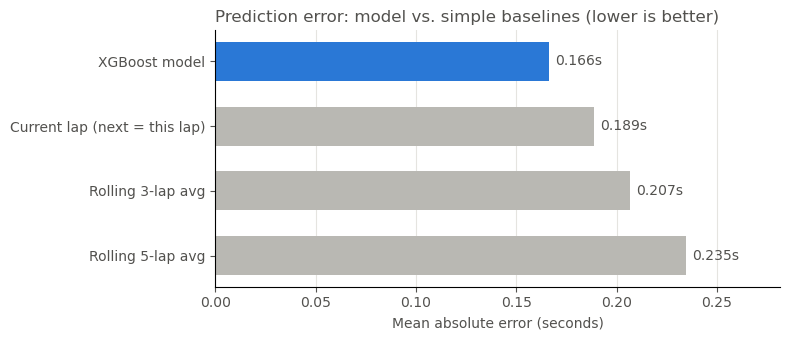

In [16]:
# Model vs. Baselines (MAE - lower is better)
################################################
MODEL_COLOR, BASELINE_COLOR, INK = '#2a78d6', '#b9b8b3', '#52514e'

plot_df = comparison.sort_values('mae', ascending=False)   # worst at top, best (model) at bottom
colors = [MODEL_COLOR if m == 'XGBoost model' else BASELINE_COLOR for m in plot_df['method']]

# Barchart plot
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(plot_df['method'], plot_df['mae'], color=colors, height=0.6)

# Value label at the end of each bar
for bar, value in zip(bars, plot_df['mae']):
    ax.text(
        value + 0.003,                          # x position: the end of the bar (its value) plus small gap
        bar.get_y() + bar.get_height() / 2,     # y position: centers the label vertically on the bar
        f"{value:.3f}s",                       # the text, e.g. "0.166 s" (3 decimals)
        va='center',                            # vertically center the text on that y position
        color=INK,                      
        fontsize=10)

ax.set_title('Prediction error: model vs. simple baselines (lower is better)', loc='left', color=INK)
ax.set_xlabel('Mean absolute error (seconds)', color=INK)
ax.set_xlim(0, plot_df['mae'].max() * 1.2)   # room for the value labels
ax.tick_params(colors=INK)
ax.grid(axis='x', color='#e5e4e0', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']: # Remove the top and right border lines of the chart
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

**Baseline Comparison Takeaway:** The simplest rule — "the next lap will match the most recent valid laptime" — is surprisingly strong, because lap times change gradually during a green-flag run. Rolling averages perform worse because they lag behind tire falloff: they include older, faster laps. The model beats the best baseline by about **12%**, mainly by anticipating how quickly each driver's tires are falling off.

## 8. Feature Importance - What is driving the predictions
Which features the model relies on most when predicting the next lap's change in pace. Scores sum to 1; higher means the model leaned on that feature more often to make its decisions.

In [11]:
# Feature Importance
# How much each feature contributed to the model's decisions (scores sum to 1).
################################################
importance_df = (
    pd.DataFrame({'feature': features, 'importance': model.feature_importances_})
    .sort_values('importance', ascending=False)
    .reset_index(drop=True))

importance_df.round(3)

,feature,importance
0,driver_pace_trend,0.271
1,position_change,0.109
2,driver_last_valid_laptime,0.105
3,laptime,0.095
4,green_flag_run_length,0.070
5,left_tire_age,0.060
6,right_tire_age,0.057
7,driver_rolling_5_lap_pace,0.055
8,driver_rolling_3_lap_pace,0.047
9,driver_relative_pace_to_field,0.045


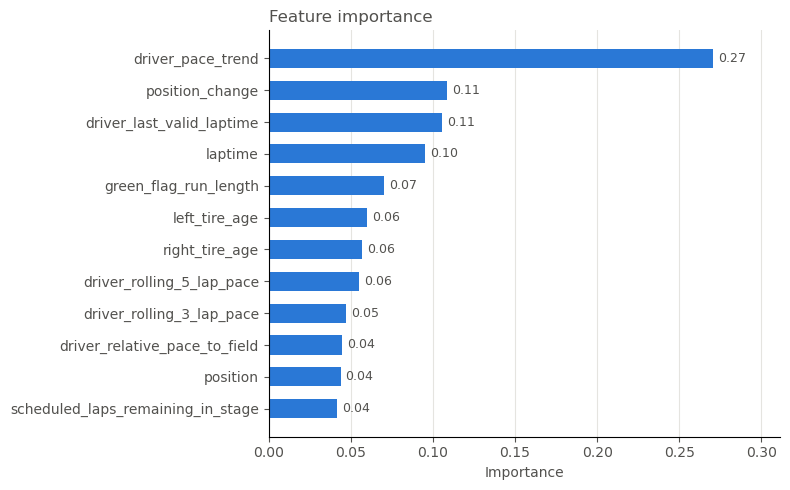

In [12]:
# Feature Importance Chart
################################################
BAR_COLOR, INK = '#2a78d6', '#52514e'

plot_df = importance_df.sort_values('importance')   # most important appears at the top

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(plot_df['feature'], plot_df['importance'], color=BAR_COLOR, height=0.6)

# Value label at the end of each bar
for bar, value in zip(bars, plot_df['importance']):
    ax.text(value + 0.003, bar.get_y() + bar.get_height() / 2, f"{value:.2f}",
            va='center', color=INK, fontsize=9)

ax.set_title('Feature importance', loc='left', color=INK)
ax.set_xlabel('Importance', color=INK)
ax.set_xlim(0, plot_df['importance'].max() * 1.15)   # create room for the value labels
ax.tick_params(colors=INK)
ax.grid(axis='x', color='#e5e4e0', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

**Feature Importance Takeaway:** `driver_pace_trend` is by far the most important feature (~27%): how quickly a driver's lap times are rising tells the model the most about the next lap — essentially, how fast the tires are falling off.

Because the model predicts the *change* in lap time, it relies on signals of tire wear and race situation rather than each car's overall speed.

In [13]:
# Error Analysis - Where Does the Model Miss?
################################################
# Add race context to each test lap (results_df rows line up with test_df rows)
context_cols = ['race_season', 'driver_name', 'Lap', 'position',
                'right_tire_age', 'green_flag_run_length', 'laptime', 'driver_pace_trend']

for col in context_cols:
    results_df[col] = test_df[col]

results_df['abs_error'] = results_df['error'].abs()   # absolute error of the miss

# How often is the model close?
for threshold in [0.10, 0.25, 0.50]:
    share = (results_df['abs_error'] <= threshold).mean()
    print(f"Within {threshold:.2f} s: {share:.1%} of laps")

# The 15 largest misses, in race order
(results_df
    .sort_values('abs_error', ascending=False)
    .head(15)
    .sort_values(['race_season', 'Lap']))

Within 0.10 s: 41.6% of laps
Within 0.25 s: 78.8% of laps
Within 0.50 s: 96.0% of laps


,actual_laptime,predicted_laptime,error,race_season,driver_name,Lap,position,right_tire_age,green_flag_run_length,laptime,driver_pace_trend,abs_error
2457,39.721,38.512940,-1.208060,2025,Justin Haley,82,11,17,5,38.937,-0.5072,1.208060
2946,39.986,38.848436,-1.137564,2025,Riley Herbst,87,28,14,10,39.040,0.1232,1.137564
3686,40.181,38.717153,-1.463847,2025,Austin Cindric,136,21,10,10,38.706,-0.0081,1.463847
1159,40.018,38.667803,-1.350197,2025,Brad Keselowski,136,22,19,10,38.650,0.0363,1.350197
2854,39.610,38.402789,-1.207211,2025,Ty Dillon,154,20,3,3,38.377,-1.1930,1.207211
206,39.550,38.065716,-1.484284,2025,Chris Buescher,164,4,13,13,38.098,0.0553,1.484284
3257,40.159,38.906579,-1.252421,2025,Noah Gragson,194,26,43,43,38.773,-0.0415,1.252421
1932,40.171,38.904918,-1.266082,2025,Christopher Bell,199,16,48,48,38.927,0.0466,1.266082
6031,40.536,39.230418,-1.305582,2026,Todd Gilliland,39,36,26,25,39.625,NaN,1.305582
6032,40.951,39.610416,-1.340584,2026,Todd Gilliland,40,36,27,26,40.536,0.7840,1.340584


**How this analysis shaped the model:** In an earlier version, the largest misses (2–3 seconds) were clustered on the *same laps across many cars*. Matching those laps against the official caution data — and reviewing race footage — showed they were laps where an incident was unfolding just before a caution was officially declared, or the final lap of a stage where cars not racing for stage points backed off.

Those laps can't be predicted from lap data alone, so laps within 5 laps of a caution were excluded from V1's scope. This reduced test MAE from about 0.176 to 0.166 seconds. Most of that gain came from removing unpredictable laps rather than from the model itself improving — the model's edge over the best baseline stayed about the same (~12%).

**Remaining large misses** include cars running well off their normal pace (e.g. damage, battle for position, or navigating traffic), which a lap-time model has no way to anticipate.

### Field Pace by Season
This chart shows the distribution of all the **clean green-flag lap times** in each race. Pit laps, caution laps, the first laps after a restart, and laps leading into a caution are already excluded. Blue = training seasons, orange = test seasons.

**How to read it:** the line inside each box is the median lap time; the box covers the middle 50% of laps; the whiskers show the typical range.

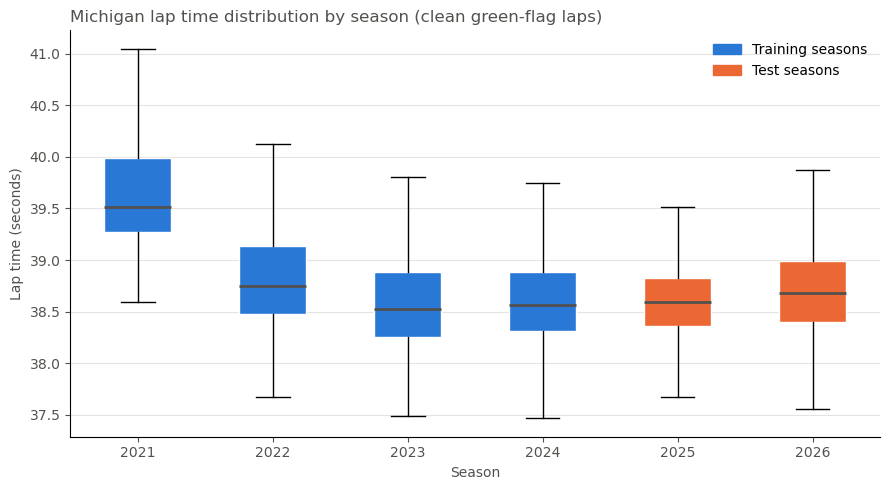

In [14]:
# Lap Time Distribution by Season (clean green-flag laps only)
# Shows how overall field pace shifts year to year - one reason the model predicts
# the CHANGE from the current lap rather than the raw lap time.
################################################
all_laps = pd.concat([train_df.assign(split='Training'), test_df.assign(split='Test')])

seasons = sorted(all_laps['race_season'].unique())
laptimes_by_season = [all_laps.loc[all_laps['race_season'] == s, 'laptime'] for s in seasons]

TRAIN_COLOR, TEST_COLOR, INK = '#2a78d6', '#eb6834', '#52514e'   # blue = training, orange = test

fig, ax = plt.subplots(figsize=(9, 5))

boxes = ax.boxplot(
    laptimes_by_season,
    tick_labels=seasons,
    patch_artist=True,           # allows filled boxes
    showfliers=False,            # hide individual outlier dots
    medianprops={'color': INK, 'linewidth': 2})

# Color each box by whether that season was used for training or testing
for box, season in zip(boxes['boxes'], seasons):
    box.set_facecolor(TRAIN_COLOR if season in train_races else TEST_COLOR)
    box.set_edgecolor('white')

# Legend (ID whats is training and what is test dataset)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=TRAIN_COLOR, label='Training seasons'),
                   Patch(color=TEST_COLOR,  label='Test seasons')],
          frameon=False, loc='upper right')

ax.set_title('Michigan lap time distribution by season (clean green-flag laps)', loc='left', color=INK)
ax.set_xlabel('Season', color=INK)
ax.set_ylabel('Lap time (seconds)', color=INK)
ax.tick_params(colors=INK)
ax.grid(axis='y', color='#e5e4e0', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

**Takeaway:** The 2021 race (the last year of the Gen-6 car) was clearly slower than every Next Gen race: the median clean lap dropped by roughly **0.75–1.0 second** from 2021 to 2022–2023.

From 2022 onward, the field's pace is remarkably stable (medians around **~38.5 – ~38.7 s**), and the test seasons (2025–2026) fall in the same range as training. Two implications for the model:
- **2021 is still useful training data** because the model predicts the *change* from the current lap — not the raw lap time — it learns patterns like tire falloff that carry over between car generations. (Removing 2021 made test accuracy worse.)

- **No large pace shift between training and test years**, which helps explain why predicting the change performed about the same as predicting the raw lap time here. The change target is more robust if a future race runs at a noticeably different overall pace.

### What the Predictions Look Like
A single driver's longest green-flag run from a test race the model never saw.

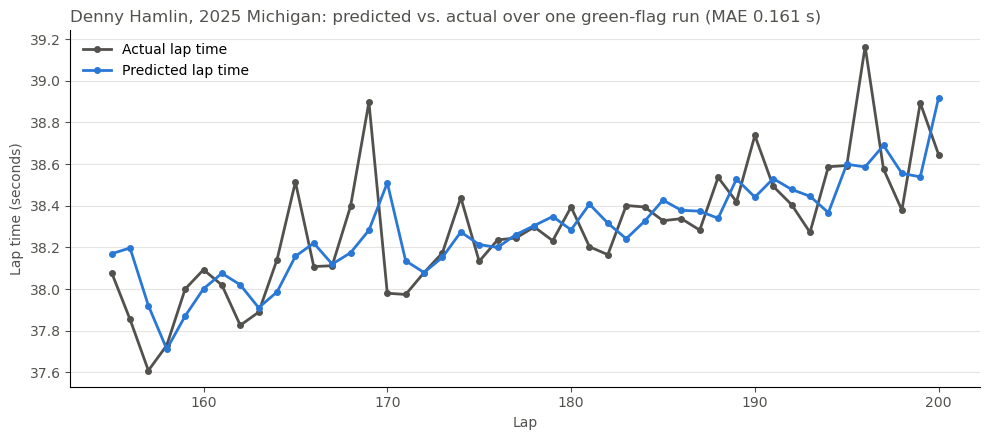

In [15]:
# Predicted vs. Actual: One Driver's Longest Green-Flag Run
################################################
SEASON = 2025
DRIVER = 'Denny Hamlin'   # change to any driver in the test races

# Put the predictions next to their lap info (rows line up with test_df)
chart_df = test_df[['race_season', 'driver_name', 'run_id', 'Lap']].copy()
chart_df['actual']    = actual_next_laptime.values
chart_df['predicted'] = predictions
chart_df['next_lap']  = chart_df['Lap'] + 1   # each row predicts the FOLLOWING lap

# Pick this driver's longest run in that race
driver_laps = chart_df[(chart_df['race_season'] == SEASON) & (chart_df['driver_name'] == DRIVER)]
longest_run = driver_laps['run_id'].value_counts().idxmax()
run = driver_laps[driver_laps['run_id'] == longest_run]

run_mae = (run['predicted'] - run['actual']).abs().mean()

# Chart
ACTUAL_COLOR, PREDICTED_COLOR, INK = '#52514e', '#2a78d6', '#52514e'

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(run['next_lap'], run['actual'],    color=ACTUAL_COLOR,    linewidth=2, marker='o', markersize=4, label='Actual lap time')
ax.plot(run['next_lap'], run['predicted'], color=PREDICTED_COLOR, linewidth=2, marker='o', markersize=4, label='Predicted lap time')

ax.set_title(f"{DRIVER}, {SEASON} Michigan: predicted vs. actual over one green-flag run (MAE {run_mae:.3f} s)",
             loc='left', color=INK)
ax.set_xlabel('Lap', color=INK)
ax.set_ylabel('Lap time (seconds)', color=INK)
ax.legend(frameon=False)
ax.tick_params(colors=INK)
ax.grid(axis='y', color='#e5e4e0', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()